# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Get the bucket name
my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)



[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.1.4     ✔ readr   2.1.5
✔ forcats 1.0.0     ✔ stringr 1.5.1
✔ ggplot2 3.5.1     ✔ tibble  3.2.1
✔ purrr   1.0.2     ✔ tidyr   1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

## Load and merge data

In [39]:
name_of_file_in_bucket <- 'Demographic_and_ancestry_covariates.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
demo  <- read_csv(name_of_file_in_bucket)

name_of_file_in_bucket <- 'adjusted_PRS_scores.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
PRS  <- read_csv(name_of_file_in_bucket) 

demo_data<-merge(demo, PRS, on="person_id", how="inner")

print(nrow(demo_data))

# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'Case_Control_df.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
Case_Control_df  <- read_csv(name_of_file_in_bucket)

merged_data<-merge(demo_data, Case_Control_df, on="person_id", how="inner")

print(nrow(merged_data))


character(0)

Rows: 135205 Columns: 47
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, income, education, where_born, military...
dbl  (27): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 135205 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adj...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 135205


character(0)

Rows: 226674 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 135041


In [40]:
library(tidyverse)
library(bigrquery)

# This query represents dataset "zip" for domain "zip_code_socioeconomic" and was generated for All of Us Controlled Tier Dataset v8
dataset_03001604_zip_code_socioeconomic_sql <- paste("
    SELECT
        observation.person_id,
        observation.observation_datetime,
        zip_code.zip3_as_string as zip_code,
        zip_code.fraction_assisted_income as assisted_income,
        zip_code.fraction_high_school_edu as high_school_education,
        zip_code.median_income,
        zip_code.fraction_no_health_ins as no_health_insurance,
        zip_code.fraction_poverty as poverty,
        zip_code.fraction_vacant_housing as vacant_housing,
        zip_code.deprivation_index,
        zip_code.acs as american_community_survey_year 
    FROM
        `zip3_ses_map` zip_code 
    JOIN
        `observation` observation 
            ON CAST(SUBSTR(observation.value_as_string, 0, STRPOS(observation.value_as_string, '*') - 1) AS INT64) = zip_code.zip3 
            AND observation_source_concept_id = 1585250 
            AND observation.value_as_string NOT LIKE 'Res%'", sep="")

# Formulate a Cloud Storage destination path for the data exported from BigQuery.
# NOTE: By default data exported multiple times on the same day will overwrite older copies.
#       But data exported on a different days will write to a new location so that historical
#       copies can be kept as the dataset definition is changed.
zip_code_socioeconomic_03001604_path <- file.path(
  Sys.getenv("WORKSPACE_BUCKET"),
  "bq_exports",
  Sys.getenv("OWNER_EMAIL"),
  strftime(lubridate::now(), "%Y%m%d"),  # Comment out this line if you want the export to always overwrite.
  "zip_code_socioeconomic_03001604",
  "zip_code_socioeconomic_03001604_*.csv")
message(str_glue('The data will be written to {zip_code_socioeconomic_03001604_path}. Use this path when reading ',
                 'the data into your notebooks in the future.'))

# Perform the query and export the dataset to Cloud Storage as CSV files.
# NOTE: You only need to run `bq_table_save` once. After that, you can
#       just read data from the CSVs in Cloud Storage.
bq_table_save(
  bq_dataset_query(Sys.getenv("WORKSPACE_CDR"), dataset_03001604_zip_code_socioeconomic_sql, billing = Sys.getenv("GOOGLE_PROJECT")),
  zip_code_socioeconomic_03001604_path,
  destination_format = "CSV")


# Read the data directly from Cloud Storage into memory.
# NOTE: Alternatively you can `gsutil -m cp {zip_code_socioeconomic_03001604_path}` to copy these files
#       to the Jupyter disk.
read_bq_export_from_workspace_bucket <- function(export_path) {
  col_types <- cols(zip3_as_string = col_character())
  bind_rows(
    map(system2('gsutil', args = c('ls', export_path), stdout = TRUE, stderr = TRUE),
        function(csv) {
          message(str_glue('Loading {csv}.'))
          chunk <- read_csv(pipe(str_glue('gsutil cat {csv}')), col_types = col_types, show_col_types = FALSE)
          if (is.null(col_types)) {
            col_types <- spec(chunk)
          }
          chunk
        }))
}
zip_code_socioeconomic_df <- read_bq_export_from_workspace_bucket(zip_code_socioeconomic_03001604_path)

dim(zip_code_socioeconomic_df)

head(zip_code_socioeconomic_df, 5)

The data will be written to gs://fc-secure-784622b3-a3b0-42a1-a555-372ab8841bd6/bq_exports/micah_hysong@researchallofus.org/20250513/zip_code_socioeconomic_03001604/zip_code_socioeconomic_03001604_*.csv. Use this path when reading the data into your notebooks in the future.

Loading gs://fc-secure-784622b3-a3b0-42a1-a555-372ab8841bd6/bq_exports/micah_hysong@researchallofus.org/20250513/zip_code_socioeconomic_03001604/zip_code_socioeconomic_03001604_000000000000.csv.

Warning message:
“The following named parsers don't match the column names: zip3_as_string”


[1] 606414     11

person_id,observation_datetime,zip_code,assisted_income,high_school_education,median_income,no_health_insurance,poverty,vacant_housing,deprivation_index,american_community_survey_year
<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
3537865,2021-11-02 20:39:15 UTC,006**,43.79415,71.04106,17819.32,5.317117,50.07648,23.339063,0.5729491,2017
5825986,2021-11-22 17:34:13 UTC,007**,42.12137,75.63601,21142.05,5.715863,46.00560,19.332183,0.5394503,2017
3354294,2023-07-17 14:12:42 UTC,007**,42.12137,75.63601,21142.05,5.715863,46.00560,19.332183,0.5394503,2017
1351851,2022-09-11 20:09:22 UTC,010**,14.42994,90.26663,63486.54,2.652506,13.92397,7.251161,0.2852150,2017
7806367,2021-03-18 16:21:39 UTC,016**,22.52714,84.99356,50685.20,3.221594,21.45395,9.305993,0.3551754,2017


In [41]:
merged_data<-merge(merged_data, zip_code_socioeconomic_df, on="person_id", how="inner")
nrow(merged_data)

merged_data$high_school_education<-1-merged_data$high_school_education

[1] 130824

In [42]:
colnames(merged_data)
sdoh_index<-c('assisted_income','high_school_education',
              'poverty','deprivation_index')
PRS_index<-c('Asthma_adjusted_score','Afib_adjusted_score','BreastC_adjusted_score',
             'CKD_adjusted_score','CHD_adjusted_score',
             'HyperC_adjusted_score','ProstateC_adjusted_score',
             't1d_adjusted_score','t2d_adjusted_score')

[1] "person_id"                      "date_of_birth"                 
 [3] "AIAN"                           "Asian"                         
 [5] "Black"                          "Mid"                           
 [7] "Multiple"                       "PI"                            
 [9] "White"                          "His"                           
[11] "race_unknown"                   "SexGender"                     
[13] "age_today"                      "ancestry_pred"                 
[15] "PC_1"                           "PC_2"                          
[17] "PC_3"                           "PC_4"                          
[19] "PC_5"                           "PC_6"                          
[21] "PC_7"                           "PC_8"                          
[23] "PC_9"                           "PC_10"                         
[25] "PC_11"                          "PC_12"                         
[27] "PC_13"                          "PC_14"                         
[29] "PC_15"                          "PC_16"                         
[31] "income"                         "education"                     
[33] "where_born"                     "military"                      
[35] "healthcare"                     "disabled"                      
[37] "sexual_orientation"             "LGBTQIA"                       
[39] "min_date"                       "max_date"                      
[41] "ehr_length"                     "relative_health"               
[43] "record_depth"                   "visit_frequency"               
[45] "age_at_last_event"              "record_depth_winsorized"       
[47] "visit_frequency_winsorized"     "Asthma_adjusted_score"         
[49] "Afib_adjusted_score"            "BreastC_adjusted_score"        
[51] "CKD_adjusted_score"             "CHD_adjusted_score"            
[53] "HyperC_adjusted_score"          "ProstateC_adjusted_score"      
[55] "t1d_adjusted_score"             "t2d_adjusted_score"            
[57] "Asthma"                         "Afib"                          
[59] "BreastC"                        "CKD"                           
[61] "CHD"                            "HyperC"                        
[63] "ProstateC"                      "t2d"                           
[65] "t1d"                            "observation_datetime"          
[67] "zip_code"                       "assisted_income"               
[69] "high_school_education"          "median_income"                 
[71] "no_health_insurance"            "poverty"                       
[73] "vacant_housing"                 "deprivation_index"             
[75] "american_community_survey_year"

# Adjust right side equation for covariates

In [43]:
library(dplyr)
library(broom)

# Define your covariates
covariates <- c("age_at_last_event", "SexGender", "record_depth", "visit_frequency")

# Create adjusted variables using residuals
for (sdoh in sdoh_index) {
  # Build the formula
  formula_str <- paste(sdoh, "~", paste(covariates, collapse = " + "))
  formula_obj <- as.formula(formula_str)
  
  # Fit model and extract residuals
  model <- lm(formula_obj, data = merged_data)
  merged_data[[paste0(sdoh, "_adj")]] <- scale(resid(model))

}


In [44]:
# Create adjusted variables using residuals
for (PRS in PRS_index) {
  # Build the formula
  formula_str <- paste(sdoh, "~", paste(covariates, collapse = " + "))
  formula_obj <- as.formula(formula_str)
  
  # Fit model and extract residuals
  model <- lm(formula_obj, data = merged_data)
  merged_data[[paste0(sdoh, "_adj")]] <- scale(resid(model))
}


# Form Quantiles

In [45]:
# Split the data into deciles
# List of diseases
diseases <- c("CKD", "CHD", "t2d")
#diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "HyperC", "ProstateC", "t2d", "t1d")

# Apply ntile() to create deciles for each disease PRS
merged_data_2 <- merged_data %>%
  mutate(across(all_of(paste0(diseases, "_adjusted_score")), 
                ~ ntile(., 5), 
                .names = "{.col}")) %>%
  rename_with(~ gsub("_adjusted_score", "_PRS_Quantile", .), all_of(paste0(diseases, "_adjusted_score")))

merged_data_2 <- merged_data_2 %>%
  mutate(
    assisted_income_Quantile = ntile(assisted_income_adj, 5),
    high_school_education_Quantile = ntile(high_school_education_adj, 5),
    poverty_Quantile = ntile(poverty_adj, 5),
    deprivation_index_Quantile = ntile(deprivation_index_adj, 5) 
  )


merged_data_2 <- merged_data_2 %>%
  rename(age = age_today)

colnames(merged_data_2)

[1] "person_id"                      "date_of_birth"                 
 [3] "AIAN"                           "Asian"                         
 [5] "Black"                          "Mid"                           
 [7] "Multiple"                       "PI"                            
 [9] "White"                          "His"                           
[11] "race_unknown"                   "SexGender"                     
[13] "age"                            "ancestry_pred"                 
[15] "PC_1"                           "PC_2"                          
[17] "PC_3"                           "PC_4"                          
[19] "PC_5"                           "PC_6"                          
[21] "PC_7"                           "PC_8"                          
[23] "PC_9"                           "PC_10"                         
[25] "PC_11"                          "PC_12"                         
[27] "PC_13"                          "PC_14"                         
[29] "PC_15"                          "PC_16"                         
[31] "income"                         "education"                     
[33] "where_born"                     "military"                      
[35] "healthcare"                     "disabled"                      
[37] "sexual_orientation"             "LGBTQIA"                       
[39] "min_date"                       "max_date"                      
[41] "ehr_length"                     "relative_health"               
[43] "record_depth"                   "visit_frequency"               
[45] "age_at_last_event"              "record_depth_winsorized"       
[47] "visit_frequency_winsorized"     "Asthma_adjusted_score"         
[49] "Afib_adjusted_score"            "BreastC_adjusted_score"        
[51] "CKD_PRS_Quantile"               "CHD_PRS_Quantile"              
[53] "HyperC_adjusted_score"          "ProstateC_adjusted_score"      
[55] "t1d_adjusted_score"             "t2d_PRS_Quantile"              
[57] "Asthma"                         "Afib"                          
[59] "BreastC"                        "CKD"                           
[61] "CHD"                            "HyperC"                        
[63] "ProstateC"                      "t2d"                           
[65] "t1d"                            "observation_datetime"          
[67] "zip_code"                       "assisted_income"               
[69] "high_school_education"          "median_income"                 
[71] "no_health_insurance"            "poverty"                       
[73] "vacant_housing"                 "deprivation_index"             
[75] "american_community_survey_year" "assisted_income_adj"           
[77] "high_school_education_adj"      "poverty_adj"                   
[79] "deprivation_index_adj"          "assisted_income_Quantile"      
[81] "high_school_education_Quantile" "poverty_Quantile"              
[83] "deprivation_index_Quantile"

# Compare corr before and after adj

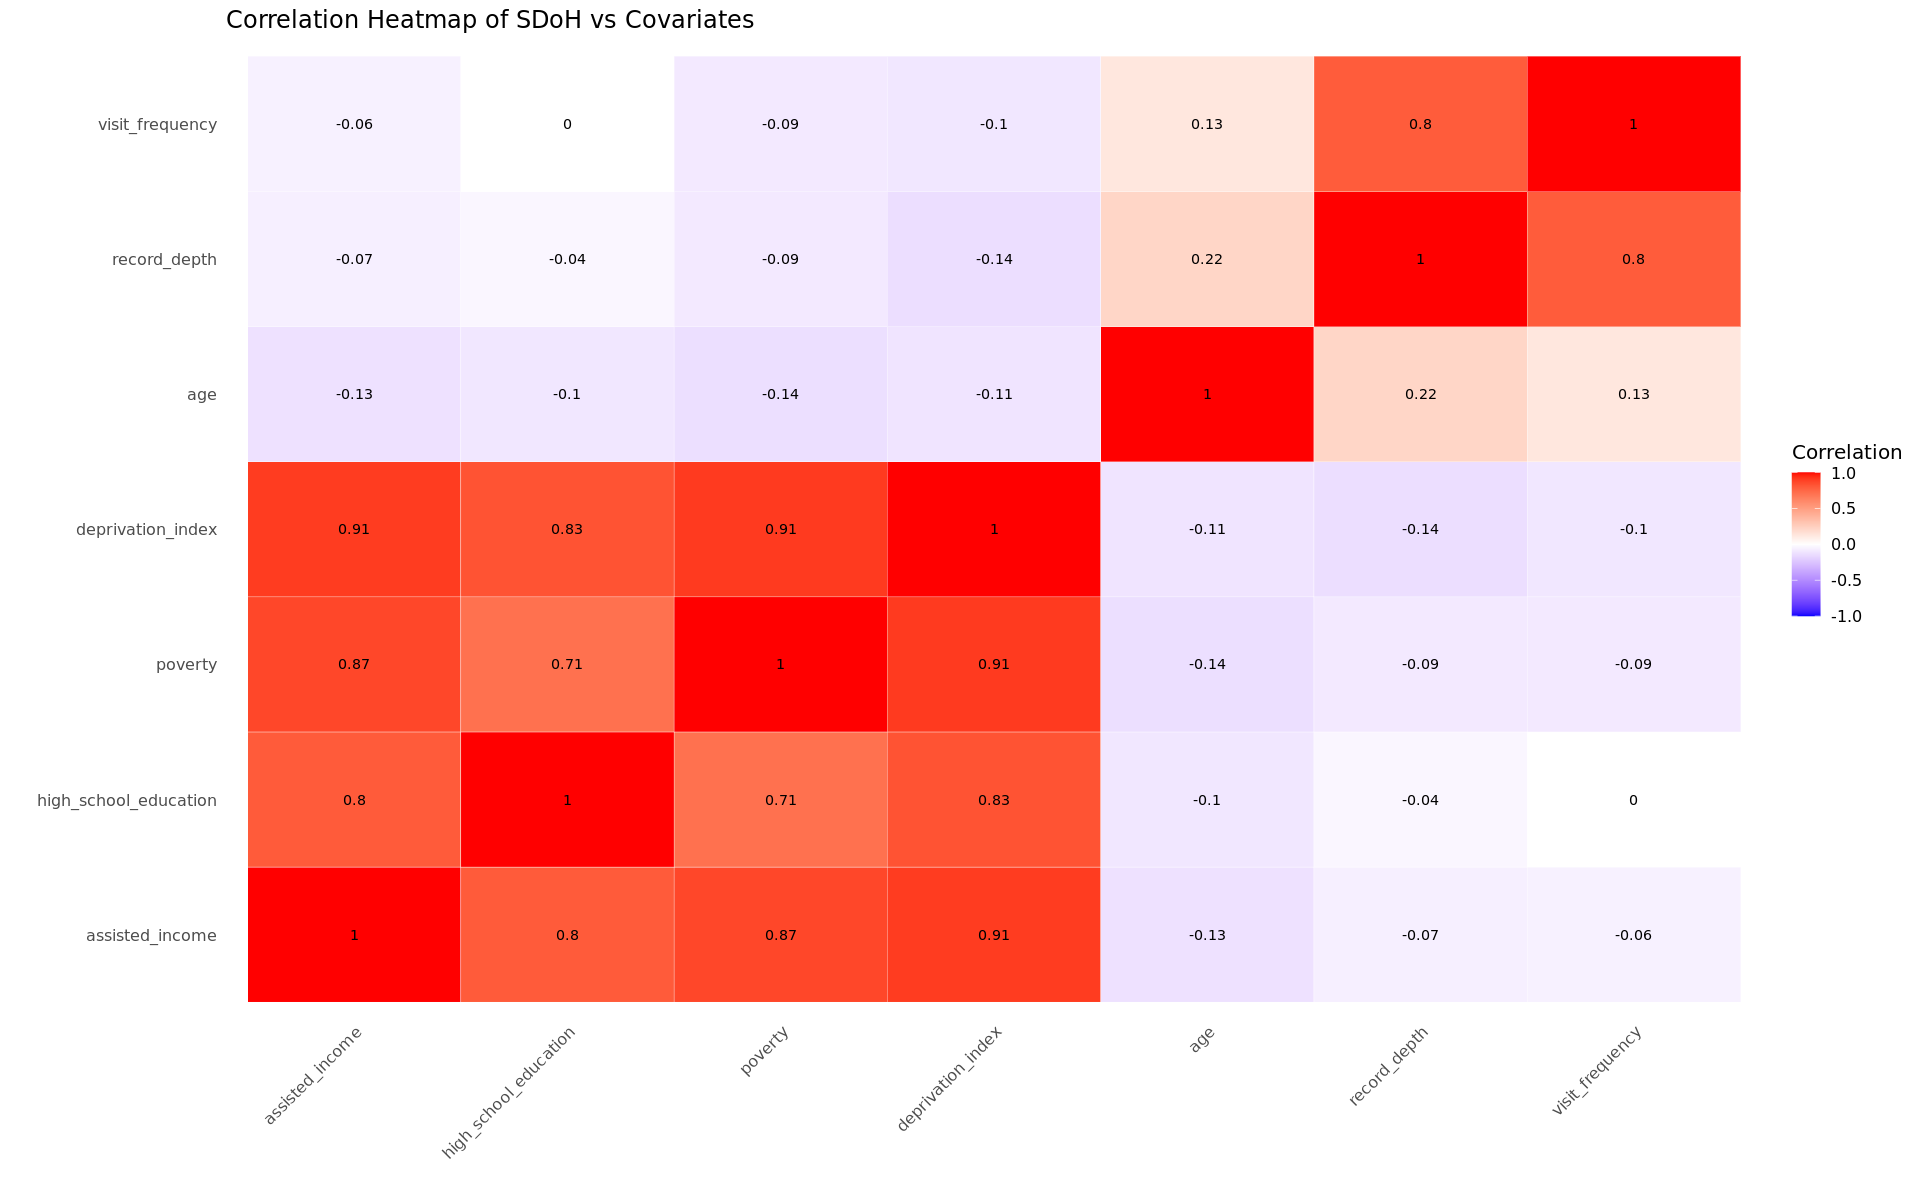

In [46]:
covariates<-c("age", "record_depth", "visit_frequency")
sdoh_index<-c('assisted_income','high_school_education',
              'poverty','deprivation_index')

cor_matrix <- merged_data_2 %>%
  select(all_of(c(sdoh_index, covariates))) %>%
  cor(use = "pairwise.complete.obs")

library(ggplot2)
library(reshape2)  # or use tidyr::pivot_longer
library(scales)

# Step 1: Compute correlation matrix
cor_matrix <- merged_data_2 %>%
  select(all_of(c(sdoh_index, covariates))) %>%
  cor(use = "pairwise.complete.obs")

# Step 2: Convert correlation matrix to long format
cor_long <- melt(cor_matrix)

ggplot(cor_long, aes(x = Var1, y = Var2, fill = value)) +
  geom_tile(color = "white") +
  geom_text(aes(label = round(value, 2)), color = "black", size = 3) + # Add values on tiles
  scale_fill_gradient2(
    low = "blue", mid = "white", high = "red",
    midpoint = 0, limit = c(-1, 1), space = "Lab",
    name = "Correlation"
  ) +
  theme_minimal(base_size = 12) +
  labs(
    title = "Correlation Heatmap of SDoH vs Covariates",
    x = "",
    y = ""
  ) +
  theme(
    axis.text.x = element_text(angle = 45, vjust = 1, hjust = 1),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank()
  )




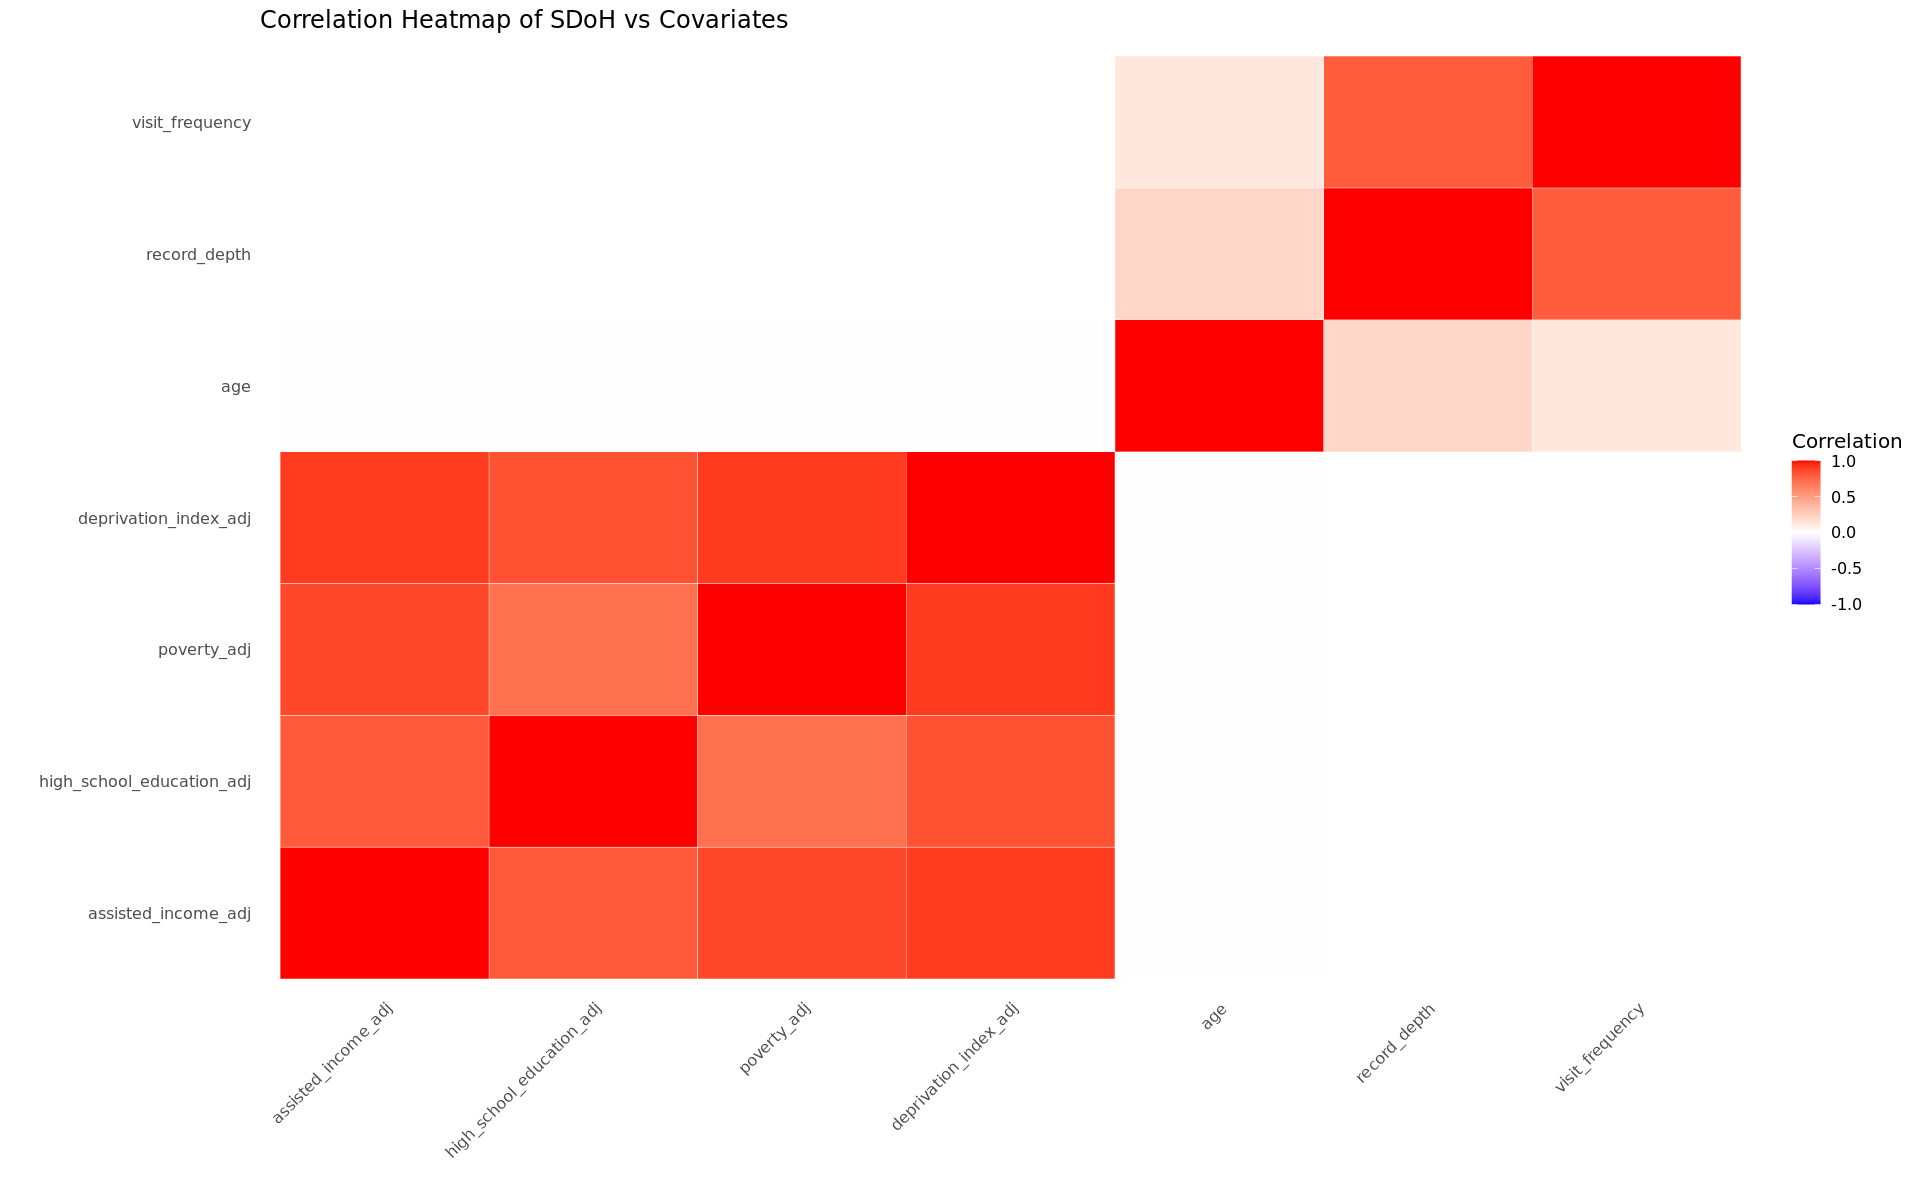

In [47]:
covariates<-c("age", "record_depth", "visit_frequency")
sdoh_index<-c('assisted_income_adj','high_school_education_adj',
              'poverty_adj','deprivation_index_adj')

cor_matrix <- merged_data_2 %>%
  select(all_of(c(sdoh_index, covariates))) %>%
  cor(use = "pairwise.complete.obs")

library(ggplot2)
library(reshape2)  # or use tidyr::pivot_longer
library(scales)

# Step 1: Compute correlation matrix
cor_matrix <- merged_data_2 %>%
  select(all_of(c(sdoh_index, covariates))) %>%
  cor(use = "pairwise.complete.obs")

# Step 2: Convert correlation matrix to long format
cor_long <- melt(cor_matrix)

# Step 3: Plot heatmap
ggplot(cor_long, aes(x = Var1, y = Var2, fill = value)) +
  geom_tile(color = "white") +
  scale_fill_gradient2(
    low = "blue", mid = "white", high = "red",
    midpoint = 0, limit = c(-1, 1), space = "Lab",
    name = "Correlation"
  ) +
  theme_minimal(base_size = 12) +
  labs(
    title = "Correlation Heatmap of SDoH vs Covariates",
    x = "",
    y = ""
  ) +
  theme(
    axis.text.x = element_text(angle = 45, vjust = 1, hjust = 1),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank()
  )


# Plot

In [48]:
# Step 1: Reshape the data into long format (from wide)
long_data <- merged_data_2 %>%
  pivot_longer(cols = all_of(diseases), 
               names_to = "Disease", 
               values_to = "Case_Control") %>%
  pivot_longer(cols = all_of(paste0(diseases, "_PRS_Quantile")), 
               names_to = "PRS_Variable", 
               values_to = "PRS_Quantile") %>%
  mutate(PRS_Variable= gsub("_PRS_Quantile", "", PRS_Variable))  %>%
  filter(Disease == PRS_Variable)  # Ensure PRS deciles match disease

long_data<- long_data[!is.na(long_data$Case_Control), ]


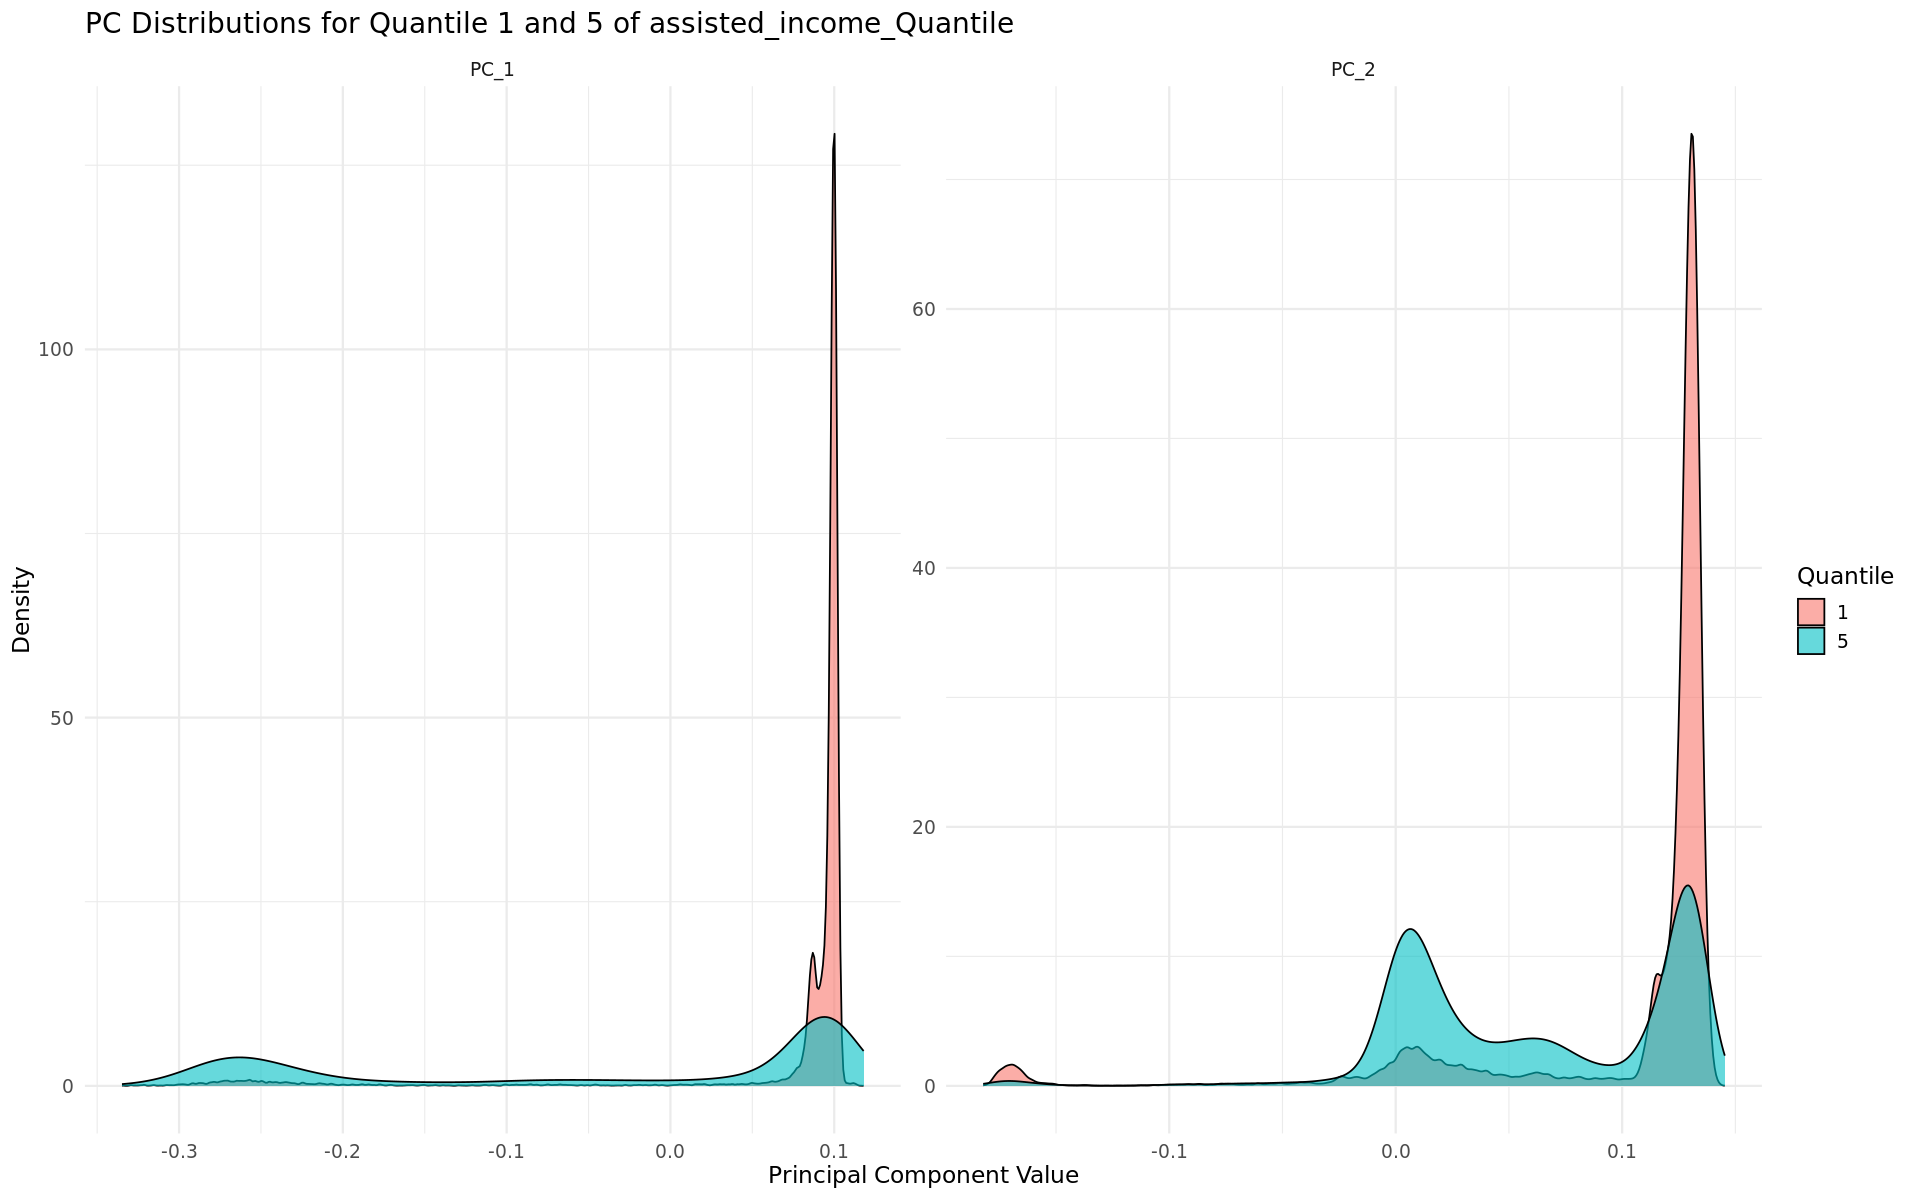

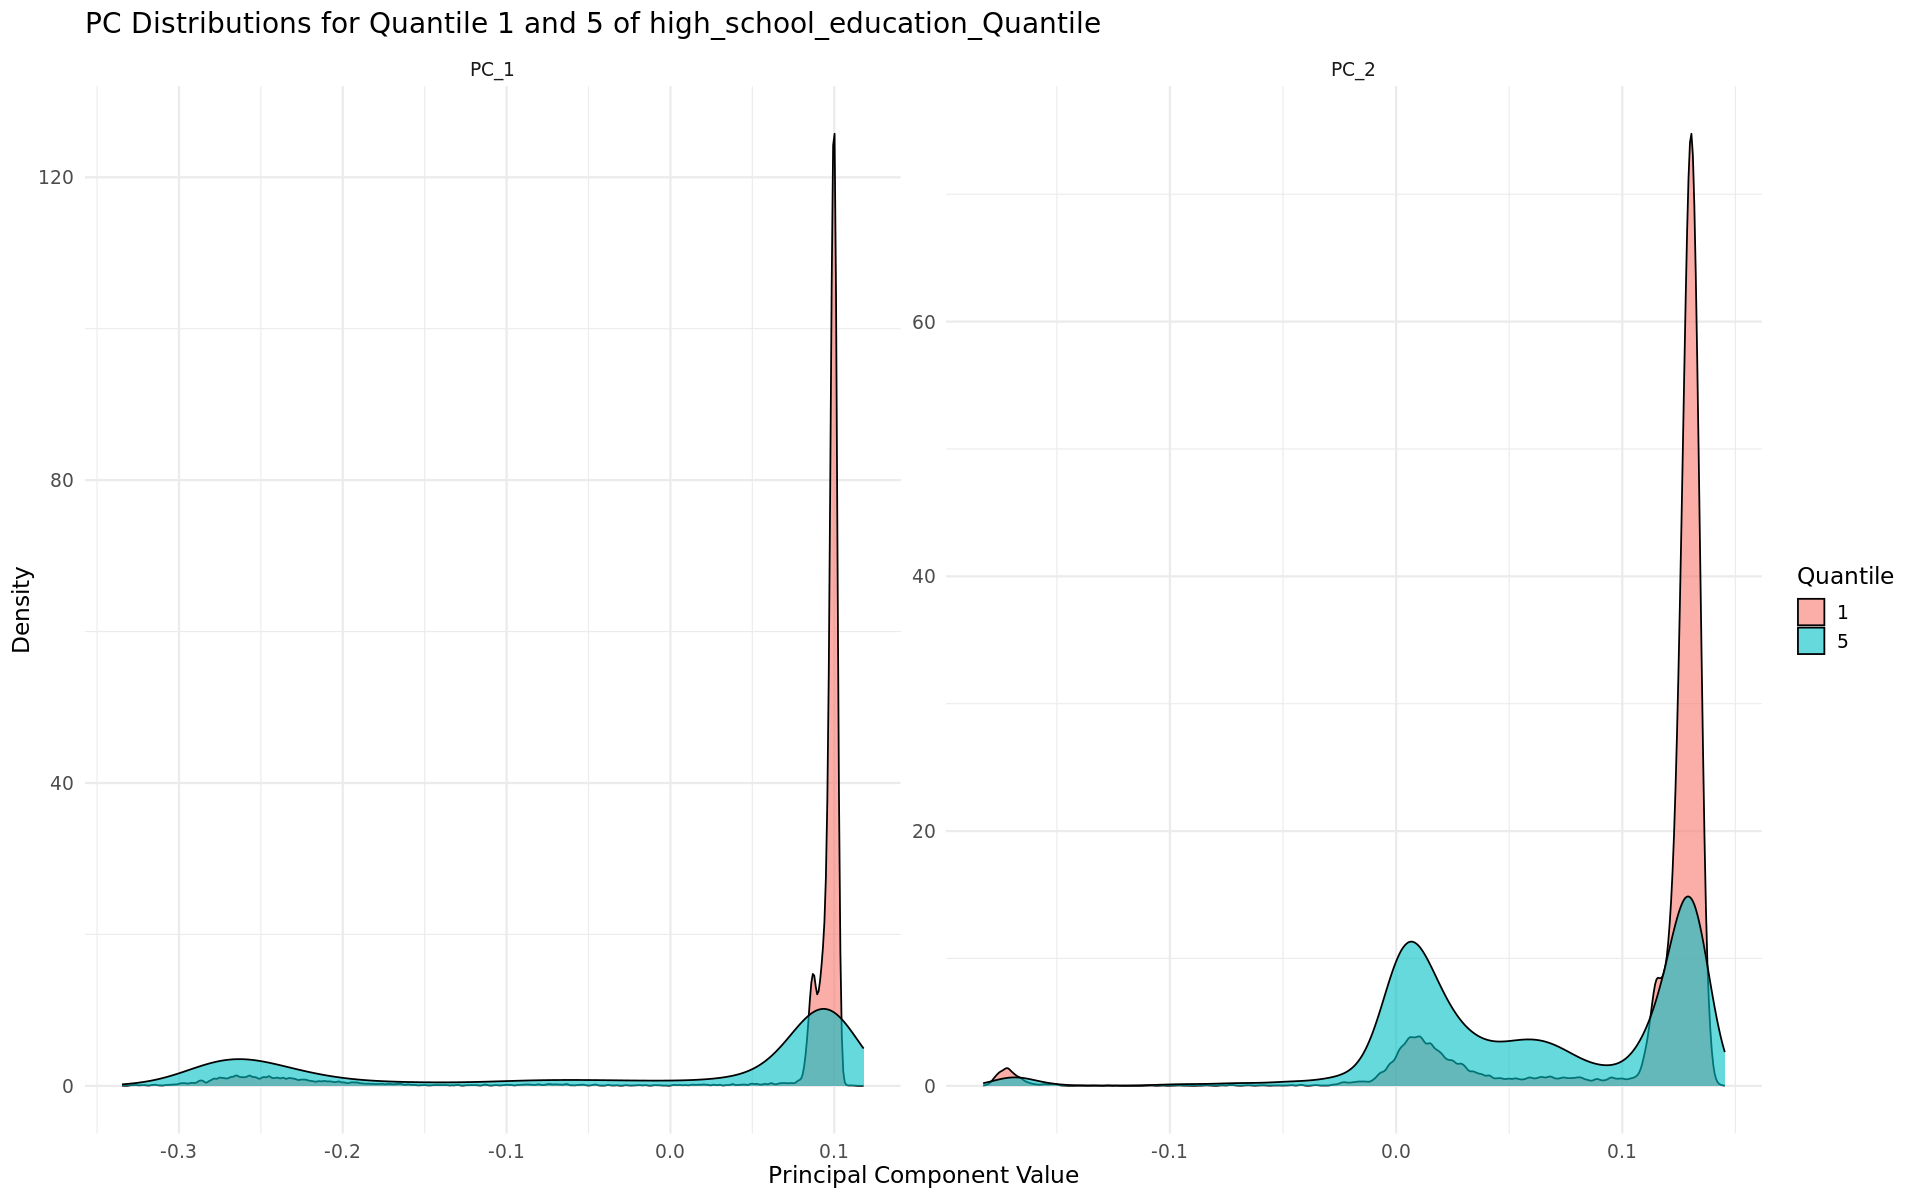

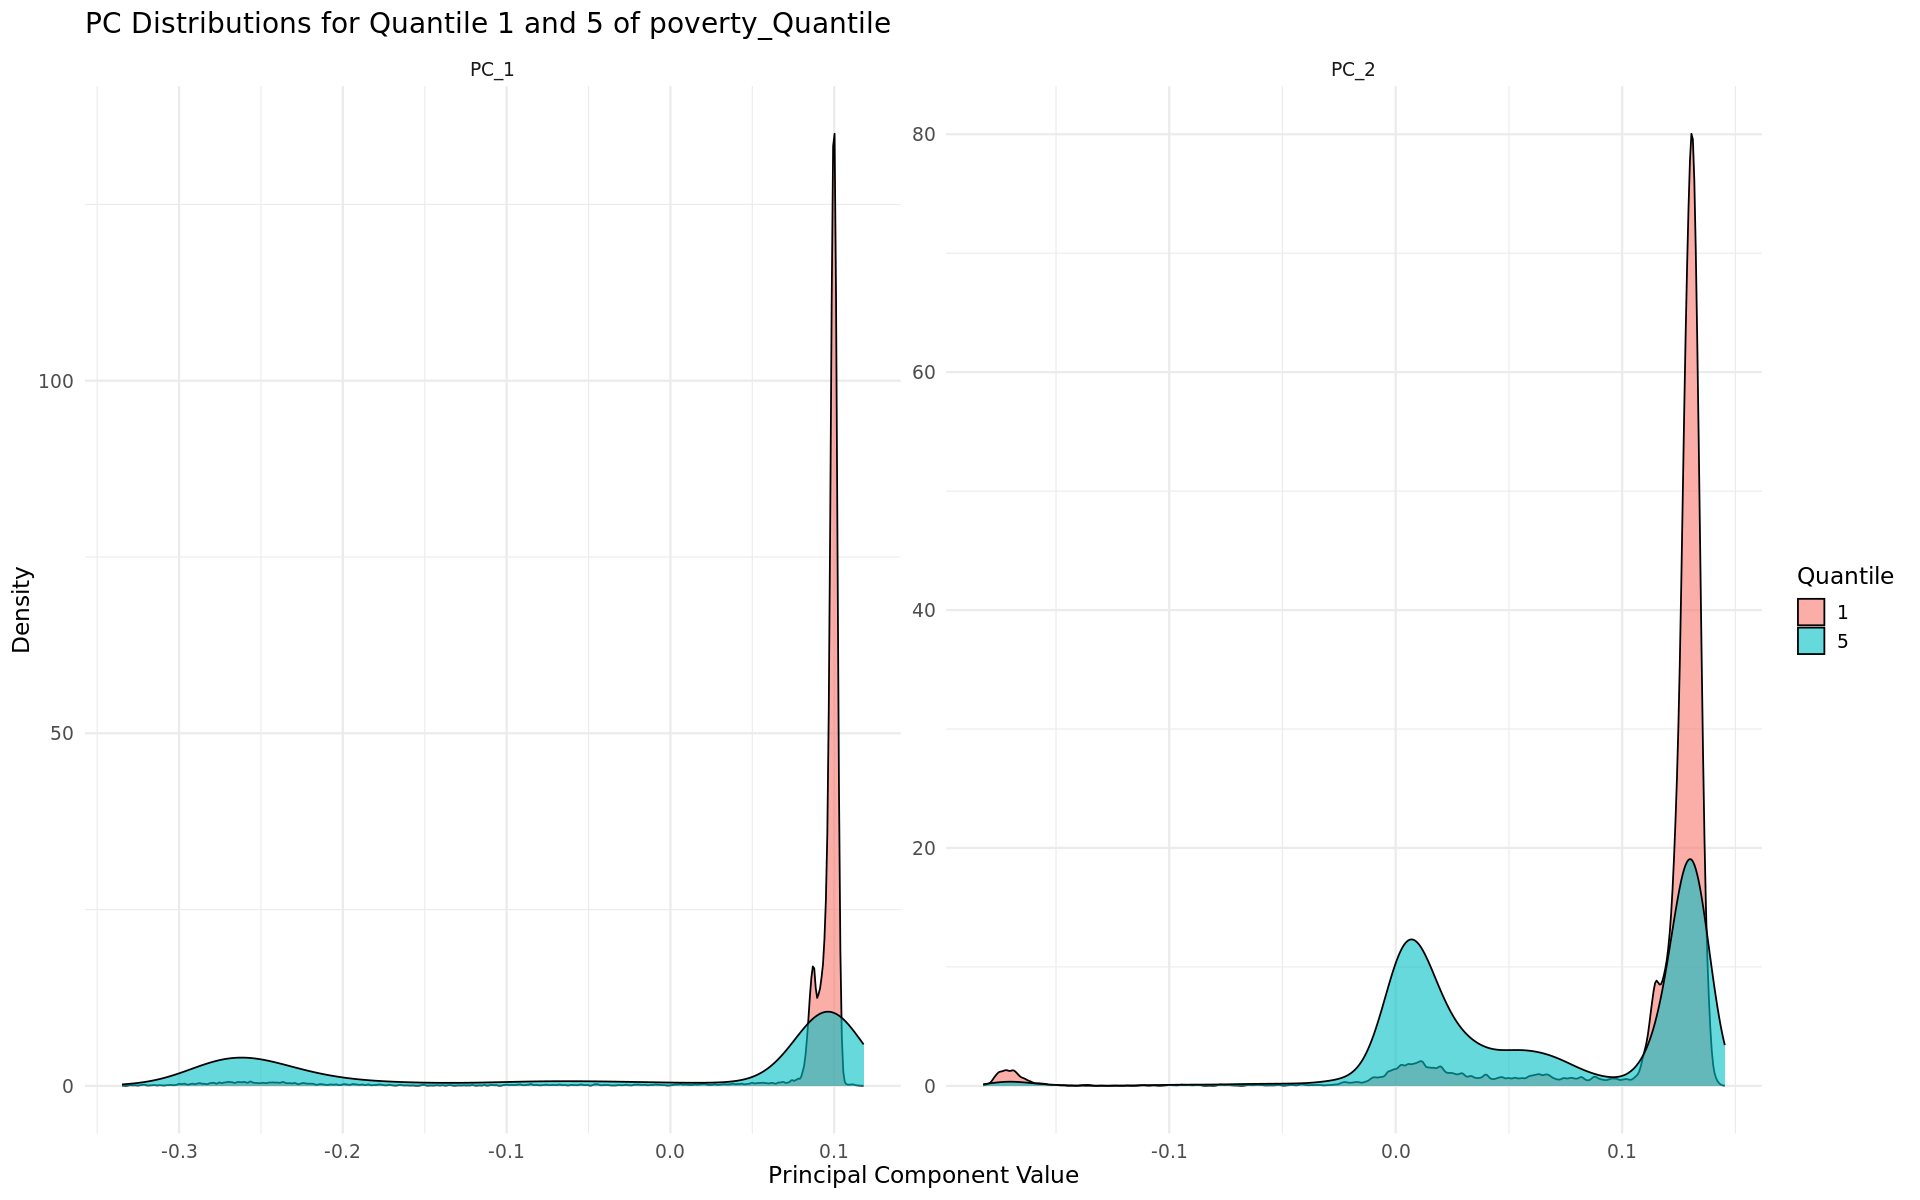

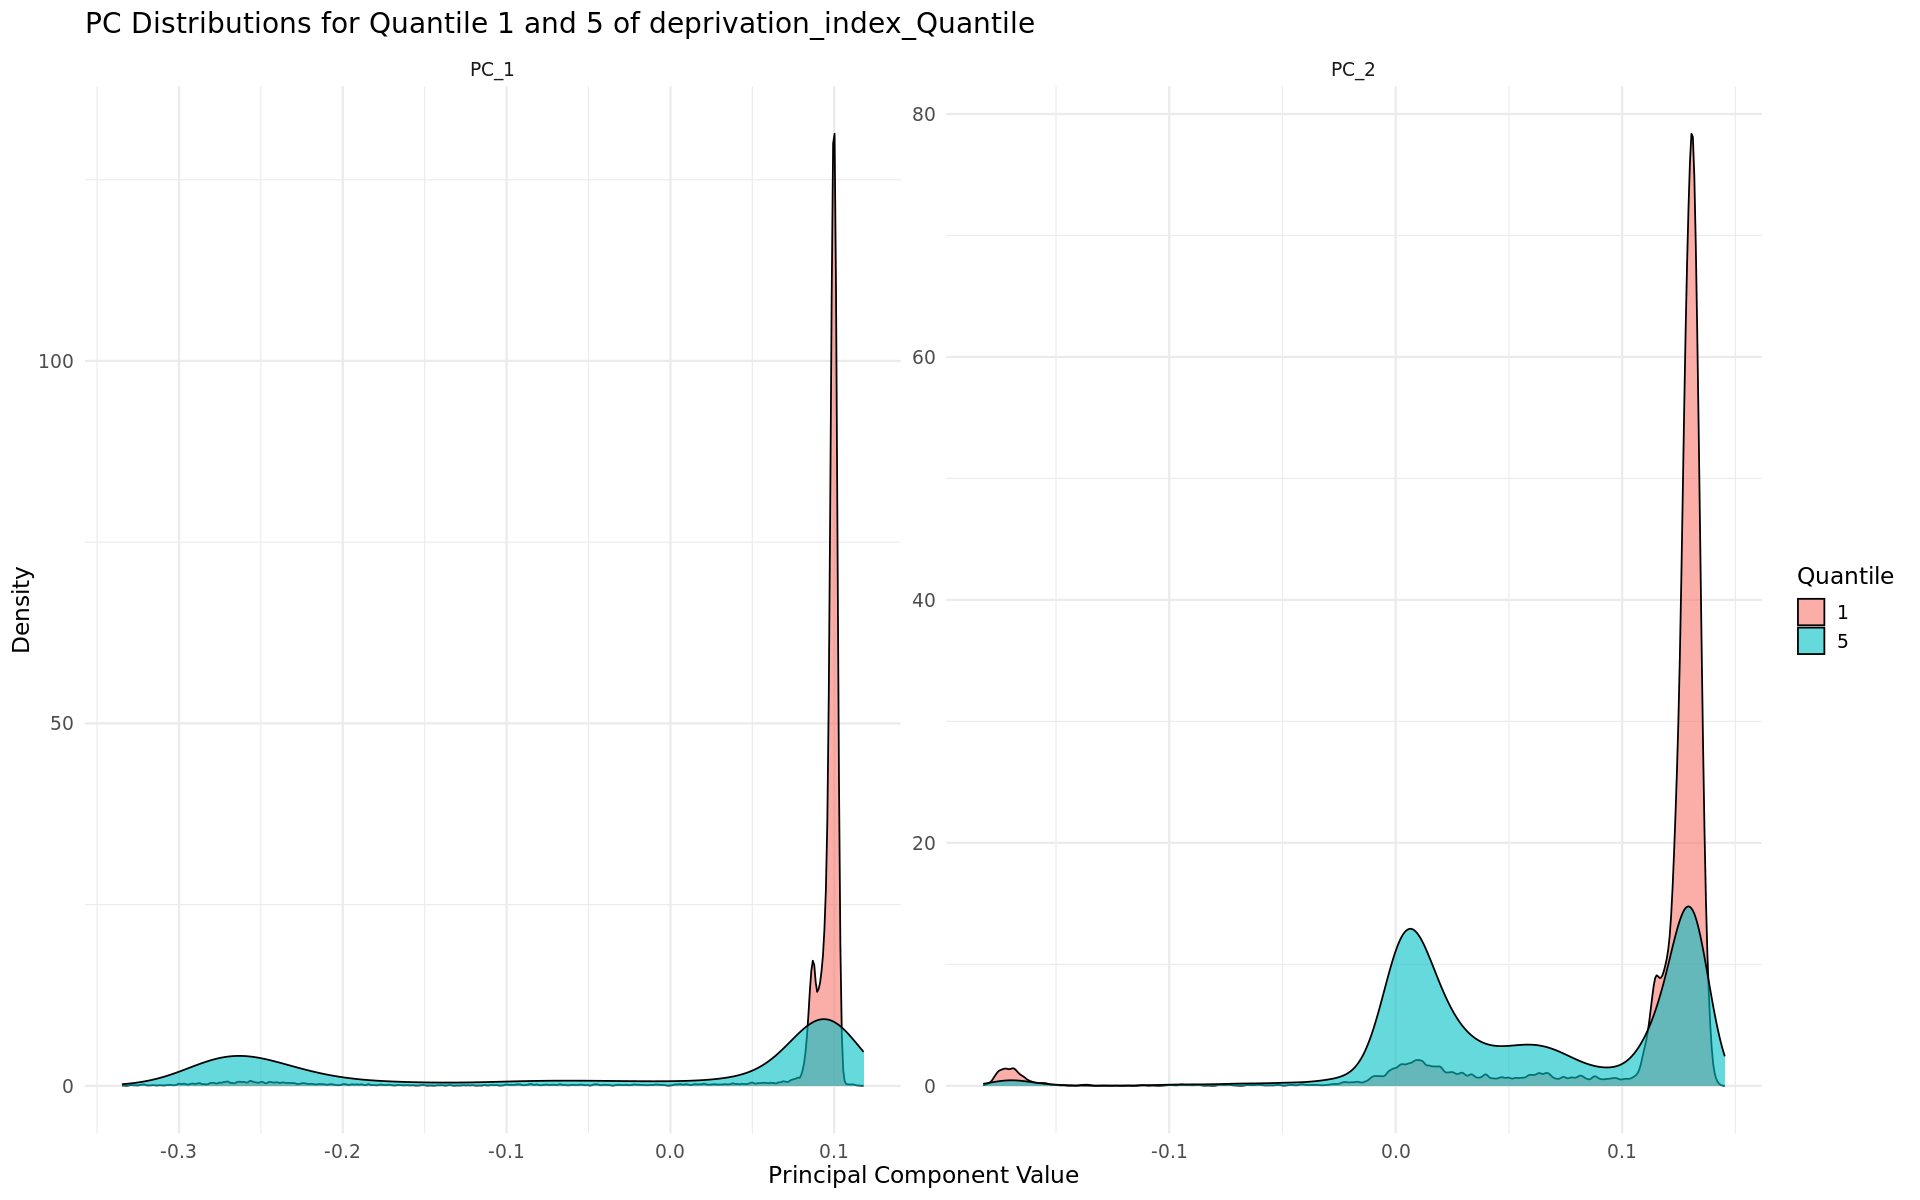

In [74]:
quantile_cols <- c(
  "assisted_income_Quantile",
  "high_school_education_Quantile",
  "poverty_Quantile",
  "deprivation_index_Quantile"
)

# Loop through each column
for (col in quantile_cols) {
  # Dynamically filter data where the column is 1 or 5
  filtered <- merged_data_2 %>%
    filter(.data[[col]] %in% c(1, 5)) %>%
    mutate(Quantile = factor(.data[[col]])) %>%
    select(PC_1, PC_2, Quantile)

  # Pivot to long format for ggplot
  long_df <- filtered %>%
    pivot_longer(cols = c(PC_1, PC_2), names_to = "PC", values_to = "value")

  # Plot
  p <- ggplot(long_df, aes(x = value, fill = Quantile)) +
    geom_density(alpha = 0.6) +
    facet_wrap(~PC, scales = "free") +
    labs(
      title = paste("PC Distributions for Quantile 1 and 5 of", col),
      x = "Principal Component Value",
      y = "Density",
      fill = "Quantile"
    ) +
    theme_minimal(base_size = 14)

  print(p)
    
}

In [84]:
# Loop through each quantile column
for (col in quantile_cols) {
  cat("\n\n====", col, "====\n")

  summary_table <- merged_data_2 %>%
    filter(.data[[col]] %in% c(1, 5)) %>%
    group_by(Quantile = .data[[col]], ancestry_pred) %>%
    summarise(n = n(), .groups = "drop") %>%
    group_by(Quantile) %>%
    mutate(percent = round(100 * n / sum(n), 1)) %>%
    ungroup() %>%
    pivot_wider(
      names_from = Quantile,
      values_from = c(n, percent),
      names_glue = "Quantile{Quantile}_{.value}"
    ) %>%
    arrange(ancestry_pred)
    
    print(summary_table)

}




==== assisted_income_Quantile ====
# A tibble: 6 × 5
  ancestry_pred Quantile1_n Quantile5_n Quantile1_percent Quantile5_percent
  <chr>               <int>       <int>             <dbl>             <dbl>
1 afr                  1487        9904               5.7              37.9
2 amr                  2387        6137               9.1              23.5
3 eas                   686         274               2.6               1  
4 eur                 21189        9580              81                36.6
5 mid                   106          74               0.4               0.3
6 sas                   310         195               1.2               0.7


==== high_school_education_Quantile ====
# A tibble: 6 × 5
  ancestry_pred Quantile1_n Quantile5_n Quantile1_percent Quantile5_percent
  <chr>               <int>       <int>             <dbl>             <dbl>
1 afr                  2853        9066              10.9              34.7
2 amr                   703        6845         

In [85]:
library(dplyr)
library(tidyr)


results_list <- list()

for (col in quantile_cols) {
  summary_table <- merged_data_2 %>%
    filter(.data[[col]] %in% c(1, 5)) %>%
    group_by(Quantile = .data[[col]]) %>%
    summarise(
      PC_1 = sprintf("%.2f (%.2f)", mean(PC_1, na.rm = TRUE), sd(PC_1, na.rm = TRUE)),
      PC_2 = sprintf("%.2f (%.2f)", mean(PC_2, na.rm = TRUE), sd(PC_2, na.rm = TRUE)),
      .groups = "drop"
    ) %>%
    mutate(Measure = col) %>%
    select(Measure, everything())

  results_list[[col]] <- summary_table
}

# Combine all into one data frame
final_summary <- bind_rows(results_list)
print(final_summary)


# A tibble: 8 × 4
  Measure                        Quantile PC_1         PC_2       
  <chr>                             <int> <chr>        <chr>      
1 assisted_income_Quantile              1 0.08 (0.08)  0.10 (0.06)
2 assisted_income_Quantile              5 -0.05 (0.16) 0.06 (0.06)
3 high_school_education_Quantile        1 0.06 (0.10)  0.11 (0.05)
4 high_school_education_Quantile        5 -0.04 (0.16) 0.06 (0.06)
5 poverty_Quantile                      1 0.08 (0.07)  0.11 (0.05)
6 poverty_Quantile                      5 -0.04 (0.16) 0.07 (0.06)
7 deprivation_index_Quantile            1 0.08 (0.08)  0.11 (0.05)
8 deprivation_index_Quantile            5 -0.05 (0.16) 0.06 (0.06)


In [49]:
sdoh_index<-c('assisted_income_Quantile','high_school_education_Quantile',
              'poverty_Quantile','deprivation_index_Quantile')

# Initialize an empty dataframe to store the combined results
combined_log_odds_data <- data.frame()

# Iterate through each variable in sdoh_index
for (sdoh in sdoh_index) {
  log_odds_data <- long_data %>%
    group_by(Disease, PRS_Quantile, !!sym(sdoh)) %>%  # Dynamically reference sdoh variable
    summarise(
      Cases = sum(Case_Control == 1, na.rm = TRUE),
      Controls = sum(Case_Control == 0, na.rm = TRUE),
      Log_Odds = log((Cases + 0.5) / (Controls + 0.5)),  # Add 0.5 to avoid log(0)
      .groups = "drop"
    ) %>%
    mutate(SDOH_Variable = sdoh)  # Add a column to indicate the current SDOH variable
  
  # Append the results into the combined dataframe
  combined_log_odds_data <- bind_rows(combined_log_odds_data, log_odds_data)
}


# Combine all sdoh_index_Quantiles into a single column
merged_data_again <- combined_log_odds_data %>%
  pivot_longer(
    cols = all_of(sdoh_index),       # Use all_of() to dynamically select columns in sdoh_index
    values_to = "sdoh_Quantile"      # Store the values in sdoh_Quantile
  ) %>%
  filter(!is.na(sdoh_Quantile))      # Remove rows where sdoh_Quantile is NA


# Filter log_odds_data to include only quantiles 1 and 5
filtered_data <- merged_data_again %>%
  filter(sdoh_Quantile %in% c(1, 5))


In [50]:
# Create a mapping for disease names
disease_labels <- c(
  "t2d" = "Type 2 \n Diabetes",
  "CHD" = "Coronary \n Heart Disease",
  "CKD" = "Chronic \n Kidney Disease"
)

sdoh_labels <- c(
  "assisted_income_Quantile" = "Assisted Income",
  "high_school_education_Quantile" = "High School Education",
  "poverty_Quantile" = "Poverty Status",
  "deprivation_index_Quantile" = "Deprivation Index"
)

Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”


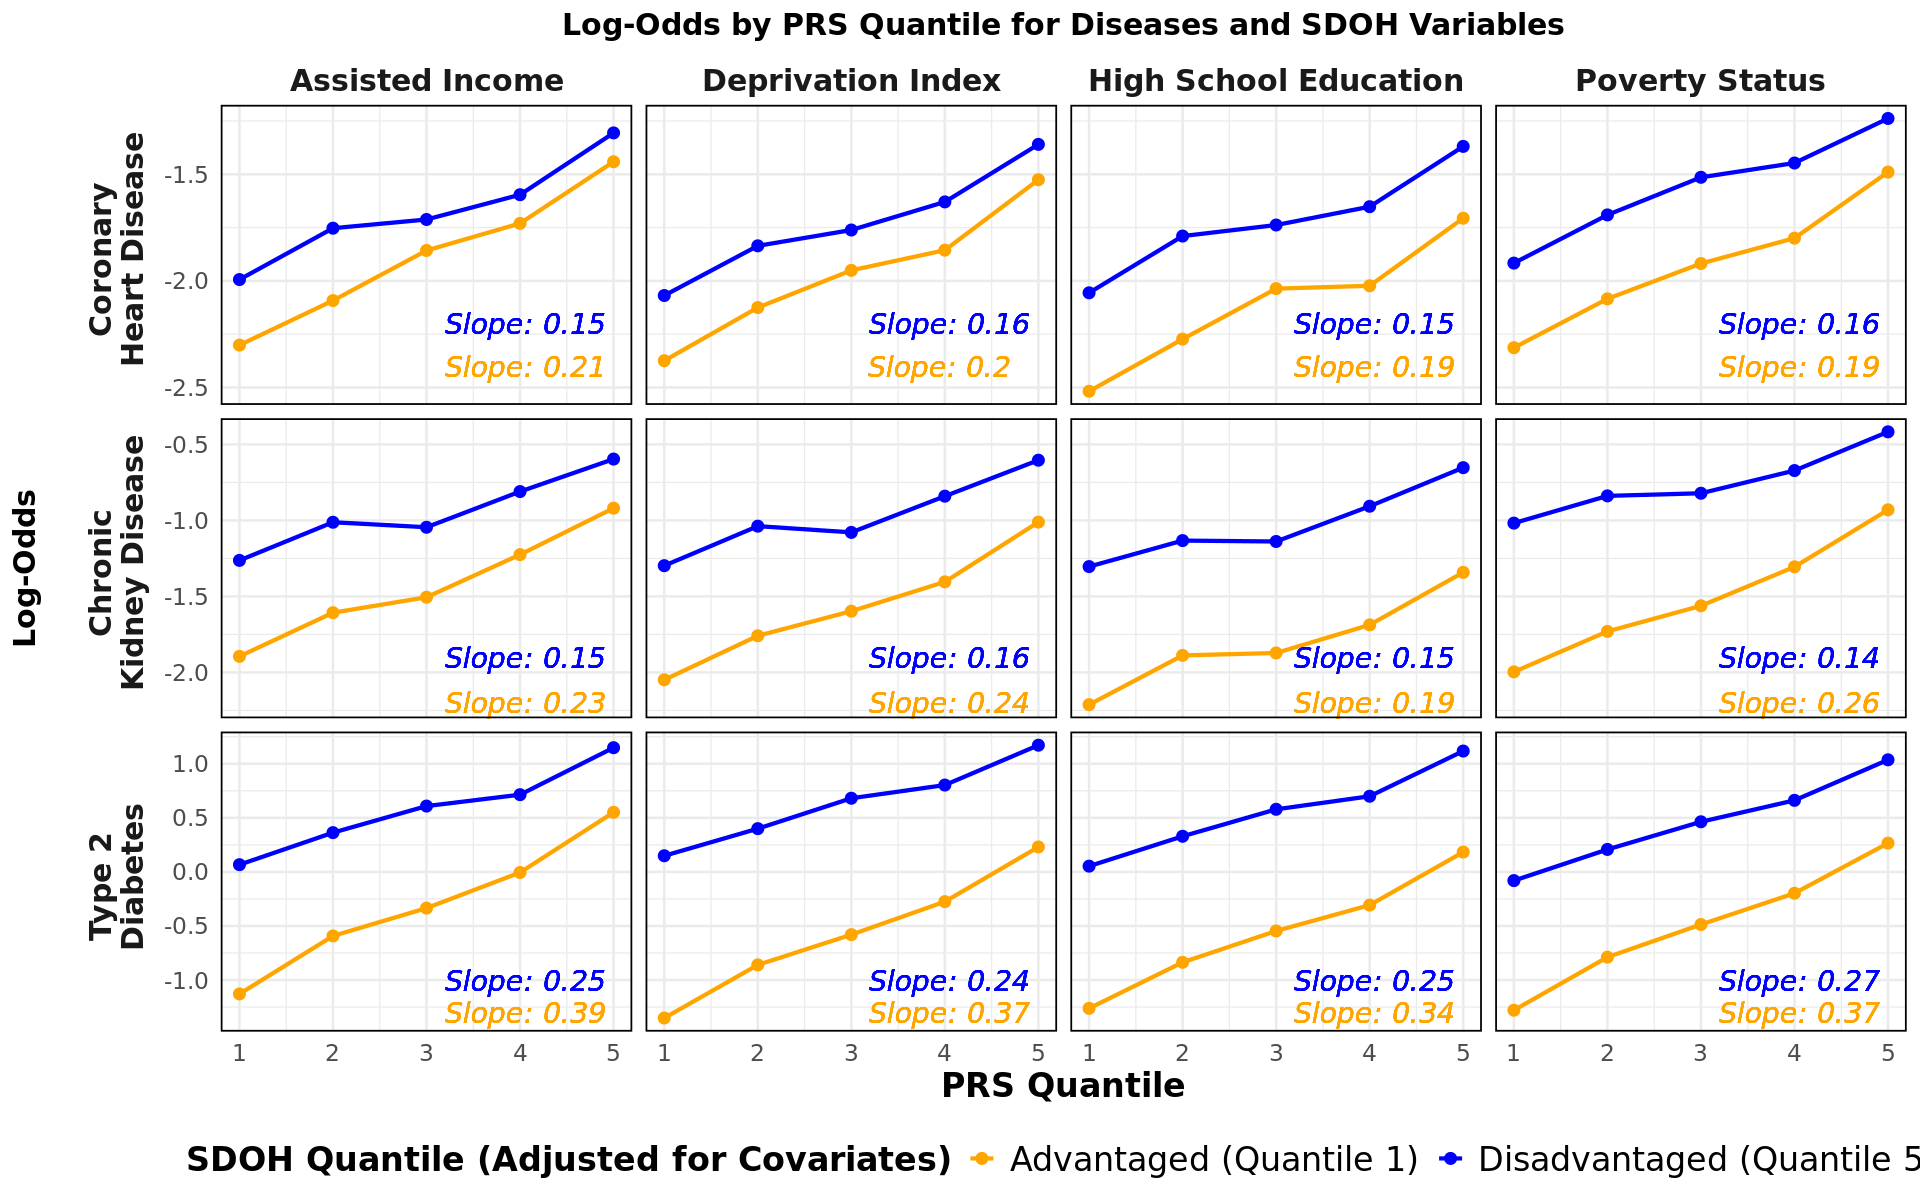

In [51]:
library(dplyr)
library(ggplot2)

slope_labels <- filtered_data %>%
  group_by(Disease, SDOH_Variable, sdoh_Quantile) %>%
  summarise(
    slope = coef(lm(Log_Odds ~ PRS_Quantile))[2],
    # Adjust x_pos and y_pos dynamically based on the disease
    x_pos = 3,
    y_pos = case_when(
      Disease == "CHD" & sdoh_Quantile == 1 ~ -2.4,  # Specific adjustment for CHD Quantile 1
      Disease == "CHD" & sdoh_Quantile == 5 ~ -2.2,  # Specific adjustment for CHD Quantile 5
      Disease == "CKD" & sdoh_Quantile == 1 ~ -2.2,  # Specific adjustment for CKD Quantile 1
      Disease == "CKD" & sdoh_Quantile == 5 ~ -1.9,  # Specific adjustment for CKD Quantile 5
      Disease == "t2d" & sdoh_Quantile == 1 ~ -1.3,
      TRUE ~ -1                                 
    ),
    .groups = "drop"
  ) %>%
  mutate(
    label = paste0("Slope: ", round(slope, 2))
  )



# Step 2: Recreate the plot with slope annotations
grid_plot <- ggplot(filtered_data, aes(x = PRS_Quantile, y = Log_Odds, color = as.factor(sdoh_Quantile), group = sdoh_Quantile)) +
  geom_line(size = 1.2) +
  geom_point(size = 3) +
  geom_text(data = slope_labels, aes(x = x_pos, y = y_pos, label = label, group = NULL), 
            hjust = -0.1, size = 6, fontface = "italic", show.legend = FALSE) +  # slope label
  facet_grid(Disease ~ SDOH_Variable, scales = "free_y", switch = "y",
             labeller = labeller(Disease = disease_labels, SDOH_Variable = sdoh_labels)) +
  scale_color_manual(
    values = c("orange", "blue"),
    labels = c("Advantaged (Quantile 1)", "Disadvantaged (Quantile 5)")
  ) +
  labs(
    title = "Log-Odds by PRS Quantile for Diseases and SDOH Variables",
    x = "PRS Quantile",
    y = "Log-Odds",
    color = "SDOH Quantile (Adjusted for Covariates)"
  ) +
  theme_minimal(base_size = 16) +
  theme(
    legend.position = "bottom",
    legend.title = element_text(size = 20, face = "bold"),
    legend.text = element_text(size = 20),
    strip.placement = "outside",
    strip.text.y.left = element_text(angle = 90, size = 18, face = "bold"),
    strip.text.x = element_text(size = 18, face = "bold"),
    axis.title.y = element_text(size = 18, face = "bold", margin = margin(r = 20)),
    axis.title.x = element_text(size = 20, face = "bold"),
    axis.text.x = element_text(size = 14),
    axis.text.y = element_text(size =14),
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5),
    panel.border = element_rect(color = "black", size = 1, fill = NA)  # Add borders between panels
  )

# Show and save the updated plot
options(repr.plot.width = 16, repr.plot.height = 10)
print(grid_plot)

ggsave("log_odds_sdoh_diseases_with_slopes.png", plot = grid_plot, width = 16, height = 10, dpi = 300)


# Supp stratified analyses

In [61]:
merged_data_eur <- merged_data |> filter(ancestry_pred=="afr")

In [62]:
colnames(merged_data_eur)

[1] "person_id"                      "date_of_birth"                 
 [3] "AIAN"                           "Asian"                         
 [5] "Black"                          "Mid"                           
 [7] "Multiple"                       "PI"                            
 [9] "White"                          "His"                           
[11] "race_unknown"                   "SexGender"                     
[13] "age_today"                      "ancestry_pred"                 
[15] "PC_1"                           "PC_2"                          
[17] "PC_3"                           "PC_4"                          
[19] "PC_5"                           "PC_6"                          
[21] "PC_7"                           "PC_8"                          
[23] "PC_9"                           "PC_10"                         
[25] "PC_11"                          "PC_12"                         
[27] "PC_13"                          "PC_14"                         
[29] "PC_15"                          "PC_16"                         
[31] "income"                         "education"                     
[33] "where_born"                     "military"                      
[35] "healthcare"                     "disabled"                      
[37] "sexual_orientation"             "LGBTQIA"                       
[39] "min_date"                       "max_date"                      
[41] "ehr_length"                     "relative_health"               
[43] "record_depth"                   "visit_frequency"               
[45] "age_at_last_event"              "record_depth_winsorized"       
[47] "visit_frequency_winsorized"     "Asthma_adjusted_score"         
[49] "Afib_adjusted_score"            "BreastC_adjusted_score"        
[51] "CKD_adjusted_score"             "CHD_adjusted_score"            
[53] "HyperC_adjusted_score"          "ProstateC_adjusted_score"      
[55] "t1d_adjusted_score"             "t2d_adjusted_score"            
[57] "Asthma"                         "Afib"                          
[59] "BreastC"                        "CKD"                           
[61] "CHD"                            "HyperC"                        
[63] "ProstateC"                      "t2d"                           
[65] "t1d"                            "observation_datetime"          
[67] "zip_code"                       "assisted_income"               
[69] "high_school_education"          "median_income"                 
[71] "no_health_insurance"            "poverty"                       
[73] "vacant_housing"                 "deprivation_index"             
[75] "american_community_survey_year" "assisted_income_adj"           
[77] "high_school_education_adj"      "poverty_adj"                   
[79] "deprivation_index_adj"

In [65]:
table(merged_data_eur$CHD)


    0     1 
22272  3761 

In [66]:
# Split the data into deciles
# List of diseases
diseases <- c("CKD", "CHD", "t2d")
#diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "HyperC", "ProstateC", "t2d", "t1d")

# Apply ntile() to create deciles for each disease PRS
merged_data_eur <- merged_data_eur %>%
  mutate(across(all_of(paste0(diseases, "_adjusted_score")), 
                ~ ntile(., 5), 
                .names = "{.col}")) %>%
  rename_with(~ gsub("_adjusted_score", "_PRS_Quantile", .), all_of(paste0(diseases, "_adjusted_score")))

merged_data_eur <- merged_data_eur %>%
  mutate(
    assisted_income_Quantile = ntile(assisted_income_adj, 5),
    high_school_education_Quantile = ntile(high_school_education_adj, 5),
    poverty_Quantile = ntile(poverty_adj, 5),
    deprivation_index_Quantile = ntile(deprivation_index_adj, 5) 
  )


merged_data_eur <- merged_data_eur %>%
  rename(age = age_today)

long_data <- merged_data_eur %>%
  pivot_longer(cols = all_of(diseases), 
               names_to = "Disease", 
               values_to = "Case_Control") %>%
  pivot_longer(cols = all_of(paste0(diseases, "_PRS_Quantile")), 
               names_to = "PRS_Variable", 
               values_to = "PRS_Quantile") %>%
  mutate(PRS_Variable= gsub("_PRS_Quantile", "", PRS_Variable))  %>%
  filter(Disease == PRS_Variable)  # Ensure PRS deciles match disease

long_data<- long_data[!is.na(long_data$Case_Control), ]

sdoh_index<-c('assisted_income_Quantile','high_school_education_Quantile',
              'poverty_Quantile','deprivation_index_Quantile')

# Initialize an empty dataframe to store the combined results
combined_log_odds_data <- data.frame()

# Iterate through each variable in sdoh_index
for (sdoh in sdoh_index) {
  log_odds_data <- long_data %>%
    group_by(Disease, PRS_Quantile, !!sym(sdoh)) %>%  # Dynamically reference sdoh variable
    summarise(
      Cases = sum(Case_Control == 1, na.rm = TRUE),
      Controls = sum(Case_Control == 0, na.rm = TRUE),
      Log_Odds = log((Cases + 0.5) / (Controls + 0.5)),  # Add 0.5 to avoid log(0)
      .groups = "drop"
    ) %>%
    mutate(SDOH_Variable = sdoh)  # Add a column to indicate the current SDOH variable
  
  # Append the results into the combined dataframe
  combined_log_odds_data <- bind_rows(combined_log_odds_data, log_odds_data)
}


# Combine all sdoh_index_Quantiles into a single column
merged_data_again <- combined_log_odds_data %>%
  pivot_longer(
    cols = all_of(sdoh_index),       # Use all_of() to dynamically select columns in sdoh_index
    values_to = "sdoh_Quantile"      # Store the values in sdoh_Quantile
  ) %>%
  filter(!is.na(sdoh_Quantile))      # Remove rows where sdoh_Quantile is NA


# Filter log_odds_data to include only quantiles 1 and 5
filtered_data <- merged_data_again %>%
  filter(sdoh_Quantile %in% c(1, 5))




Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”


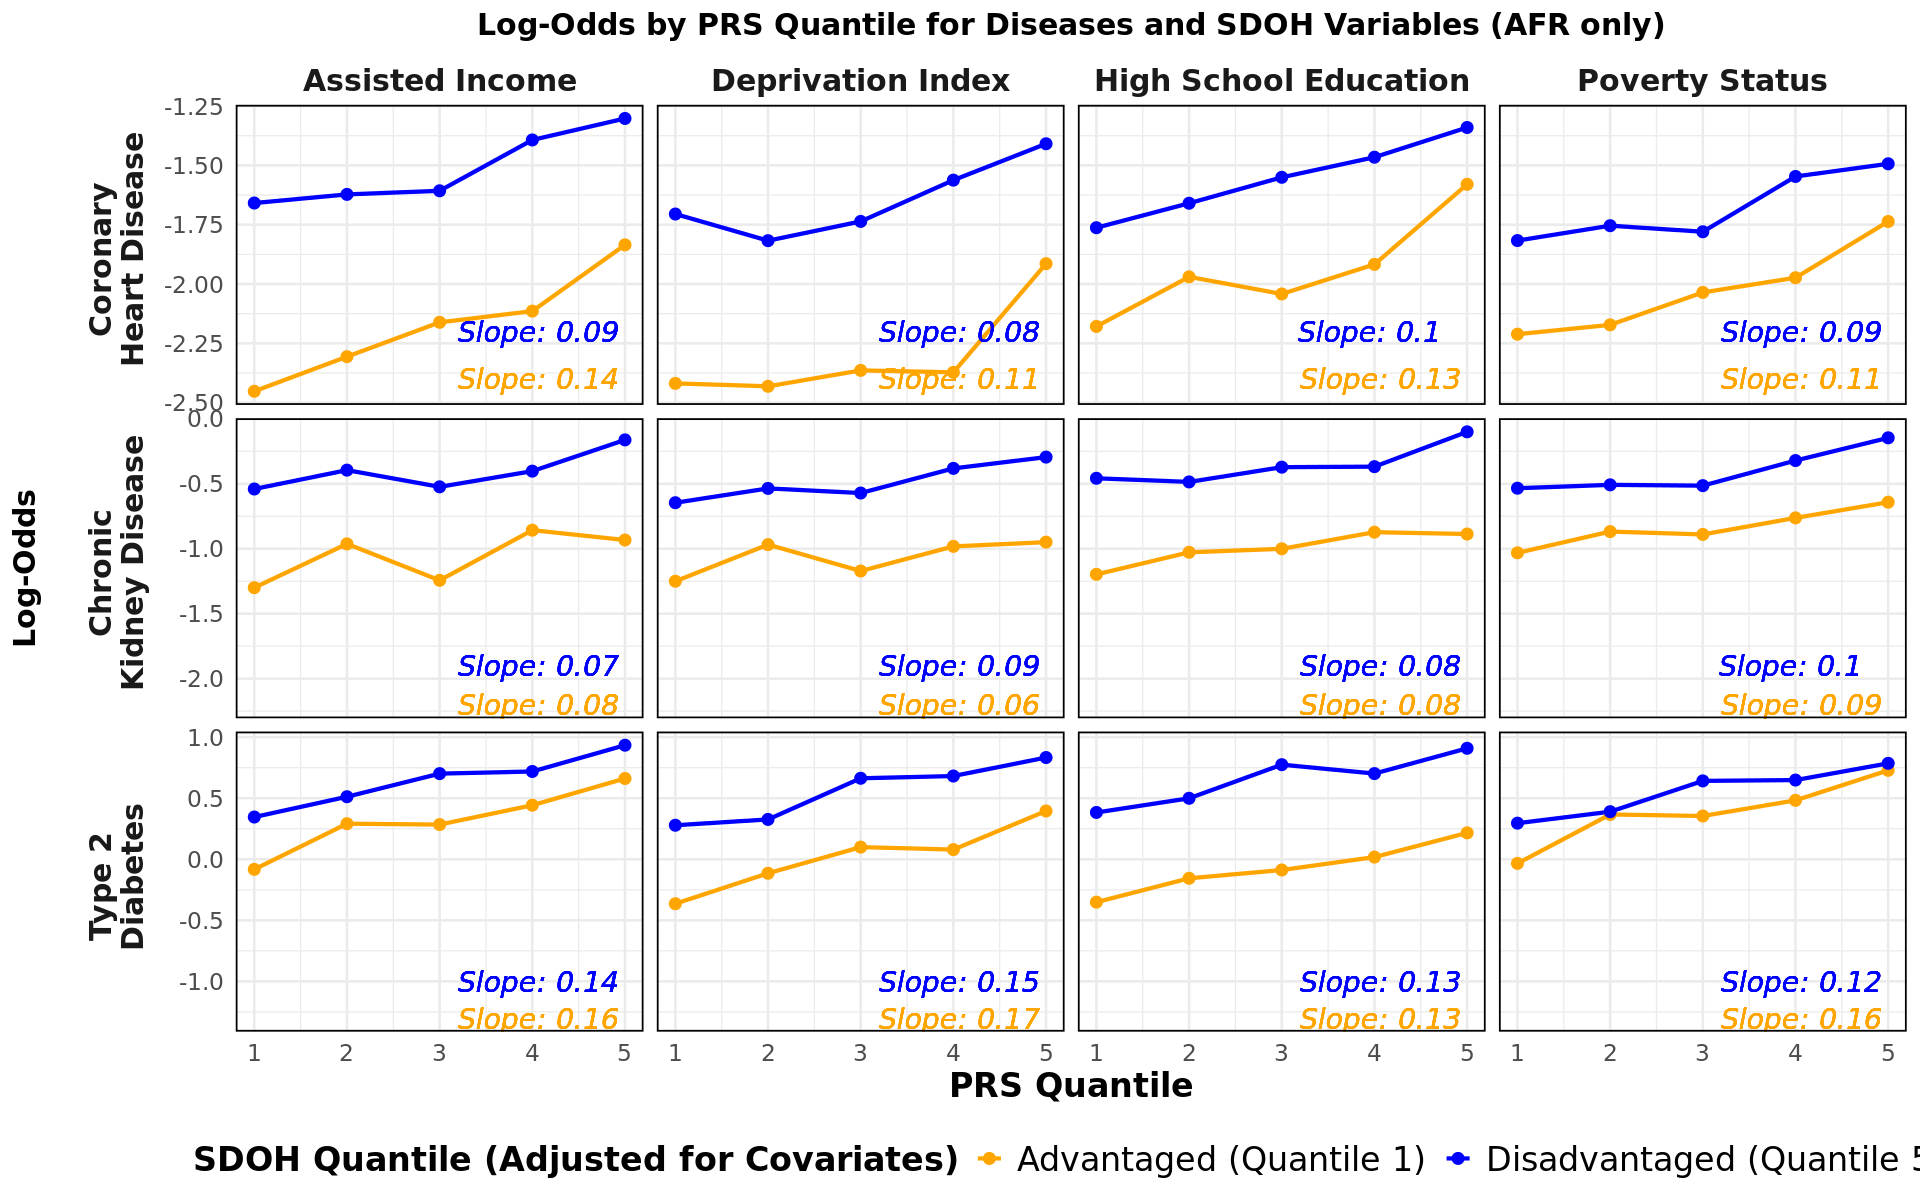

In [68]:
# Create a mapping for disease names
disease_labels <- c(
  "t2d" = "Type 2 \n Diabetes",
  "CHD" = "Coronary \n Heart Disease",
  "CKD" = "Chronic \n Kidney Disease"
)

sdoh_labels <- c(
  "assisted_income_Quantile" = "Assisted Income",
  "high_school_education_Quantile" = "High School Education",
  "poverty_Quantile" = "Poverty Status",
  "deprivation_index_Quantile" = "Deprivation Index"
)

slope_labels <- filtered_data %>%
  group_by(Disease, SDOH_Variable, sdoh_Quantile) %>%
  summarise(
    slope = coef(lm(Log_Odds ~ PRS_Quantile))[2],
    # Adjust x_pos and y_pos dynamically based on the disease
    x_pos = 3,
    y_pos = case_when(
      Disease == "CHD" & sdoh_Quantile == 1 ~ -2.4,  # Specific adjustment for CHD Quantile 1
      Disease == "CHD" & sdoh_Quantile == 5 ~ -2.2,  # Specific adjustment for CHD Quantile 5
      Disease == "CKD" & sdoh_Quantile == 1 ~ -2.2,  # Specific adjustment for CKD Quantile 1
      Disease == "CKD" & sdoh_Quantile == 5 ~ -1.9,  # Specific adjustment for CKD Quantile 5
      Disease == "t2d" & sdoh_Quantile == 1 ~ -1.3,
      TRUE ~ -1                                 
    ),
    .groups = "drop"
  ) %>%
  mutate(
    label = paste0("Slope: ", round(slope, 2))
  )



# Step 2: Recreate the plot with slope annotations
grid_plot <- ggplot(filtered_data, aes(x = PRS_Quantile, y = Log_Odds, color = as.factor(sdoh_Quantile), group = sdoh_Quantile)) +
  geom_line(size = 1.2) +
  geom_point(size = 3) +
  geom_text(data = slope_labels, aes(x = x_pos, y = y_pos, label = label, group = NULL), 
            hjust = -0.1, size = 6, fontface = "italic", show.legend = FALSE) +  # slope label
  facet_grid(Disease ~ SDOH_Variable, scales = "free_y", switch = "y",
             labeller = labeller(Disease = disease_labels, SDOH_Variable = sdoh_labels)) +
  scale_color_manual(
    values = c("orange", "blue"),
    labels = c("Advantaged (Quantile 1)", "Disadvantaged (Quantile 5)")
  ) +
  labs(
    title = "Log-Odds by PRS Quantile for Diseases and SDOH Variables (AFR only)",
    x = "PRS Quantile",
    y = "Log-Odds",
    color = "SDOH Quantile (Adjusted for Covariates)"
  ) +
  theme_minimal(base_size = 16) +
  theme(
    legend.position = "bottom",
    legend.title = element_text(size = 20, face = "bold"),
    legend.text = element_text(size = 20),
    strip.placement = "outside",
    strip.text.y.left = element_text(angle = 90, size = 18, face = "bold"),
    strip.text.x = element_text(size = 18, face = "bold"),
    axis.title.y = element_text(size = 18, face = "bold", margin = margin(r = 20)),
    axis.title.x = element_text(size = 20, face = "bold"),
    axis.text.x = element_text(size = 14),
    axis.text.y = element_text(size =14),
    plot.title = element_text(size = 18, face = "bold", hjust = 0.5),
    panel.border = element_rect(color = "black", size = 1, fill = NA)  # Add borders between panels
  )

# Show and save the updated plot
options(repr.plot.width = 16, repr.plot.height = 10)
print(grid_plot)

ggsave("log_odds_sdoh_diseases_with_slopes.png", plot = grid_plot, width = 16, height = 10, dpi = 300)
